# The PACO Algorithm 

In [ ]:
# Install directly in the global environment or create a virtual environment (recommended) and install the dependencies with:
%pip install -r requirements.txt

### Loading Data (FITS) 

In [ ]:
import os 
from vip_hci.fits import open_fits

# Your data directory
path = './data/system/' 

cube_path = os.path.join(path, 'center_im.fits')
derotation_angs_path = os.path.join(path, 'rotnth.fits')   
psf_path = os.path.join(path, 'median_unsat.fits')

cube = open_fits(cube_path)
psf = open_fits(psf_path)
derotation_angs = open_fits(derotation_angs_path)

Paco works in a single wavelenght ADI sequence so you should check the dimensions of your data and extract the wavelenght you want to use 

In [ ]:
print("Cube shape:", cube.shape)
print("Angles shape:", derotation_angs.shape)
print("PSF shape:", psf.shape)

# Extracting the first wavelength of the cube and psf if they are multi-wavelength data
if len(cube.shape) >= 4 and len(psf.shape) >= 3:
    cube = cube[0]
    psf = psf[0]

print("New cube shape in single wavelength:", cube.shape)
print("New psf shape in single wavelength:", psf.shape)

Cube shape: (61, 101, 101)
Angles shape: (61,)
PSF shape: (39, 39)
New cube shape in single wavelength: (61, 101, 101)
New psf shape in single wavelength: (39, 39)


If the dimension of your PSF is still a 3 dimensional array (stack of PSFs), PACO handles this internally by setting the PSF as the median of the stack of PSFs in the initialization function of the main class. Feel free to change this if you want a different behavior.

Now, the only parameters that we need are the FWHM and the flux-normalized PSF in order to establish the patch size the algorithm it's going to use. We can obtain this with the normalize_psf() function from VIP.

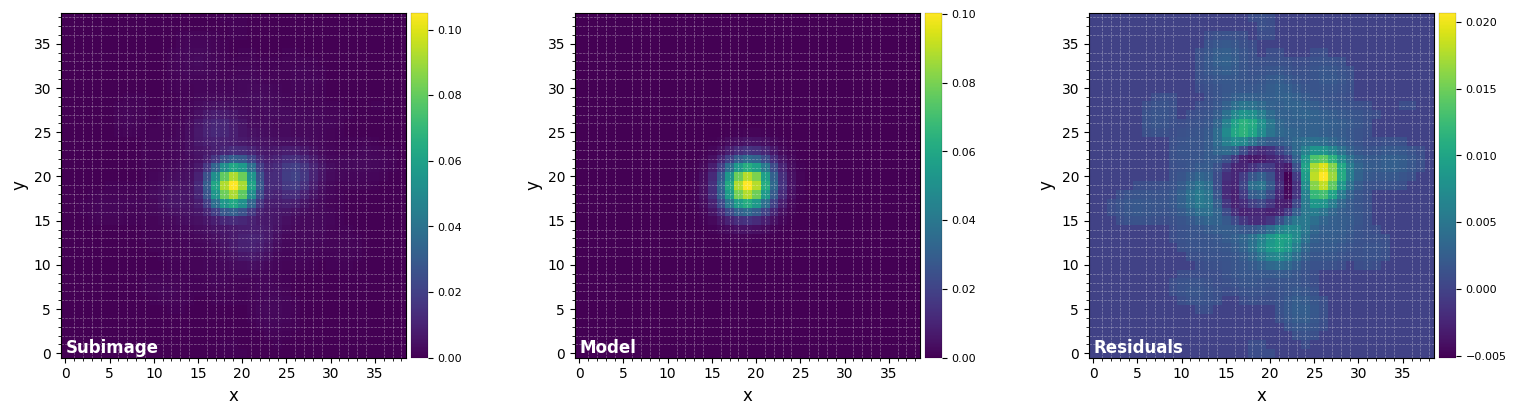

FWHM_y = 4.675842855868446
FWHM_x = 4.9261143969758745 

centroid y = 19.01099291139547
centroid x = 19.019181745331544
centroid y subim = 19.01099291139547
centroid x subim = 19.019181745331544 

amplitude = 0.10032163645468516
theta = 51.55732538820295

Mean FWHM: 4.801
Flux in 1xFWHM aperture: 1.307


In [ ]:
from vip_hci.fm import normalize_psf

norm_psf, _, fwhm = normalize_psf(psf, debug=True, full_output=True)

### Full PACO detection (Algorithm 1 of the paper)

In [ ]:
from os import cpu_count
from src.full_paco import FullPACO
from hciplot import plot_frames

# Initialize PACO with the required parameters
paco = FullPACO(cube=cube, angles=derotation_angs, psf=psf, fwhm=fwhm, verbose=True)

# Run PACO, this setup uses GPU if available and no parallel processing in CPU, set cpu to an integer > 1 to use multiprocessing.
full_snr, full_flux = paco.run(use_gpu=True, full_output=True, cpu=1)

# Plot the results
plot_frames((full_snr, full_flux), title=["SNR Map Full PACO", "Flux Map Full PACO"])

💡 Performance Tip: CPU vs. GPU Usage

Avoid running GPU and CPU multiprocessing together, as the overhead from the CUDA context will slow down your processing.

* Large Datasets: Use CPU multiprocessing alone for the best speed. You should run tests in your machine to find the optimal number of cores.

* Small Datasets: Use the GPU alone for optimal performance.

## Fast PACO detection (Algorithm 2 of the paper)

---------------------- 
Summary of PACO setup: 

Image Cube shape = (61, 101, 101)
PIXSCALE = 0.02719
PSF |  Area  |  Rad   |  Width | 
    |   69   |  4.80097862642216    |  039   | 
Patch width: 11
---------------------- 

Precomputing background statistics...
Precomputing Statistics using 6 Processes...
Patch generation took 6.04 seconds
Precomputing c and d maps...

Mean FWHM: 4.801
Flux in 1xFWHM aperture: 1.307
Precomputation took 24.13 seconds
Running Fast PACO with interpolation (order=1)...
Fast PACO took 46.50 seconds


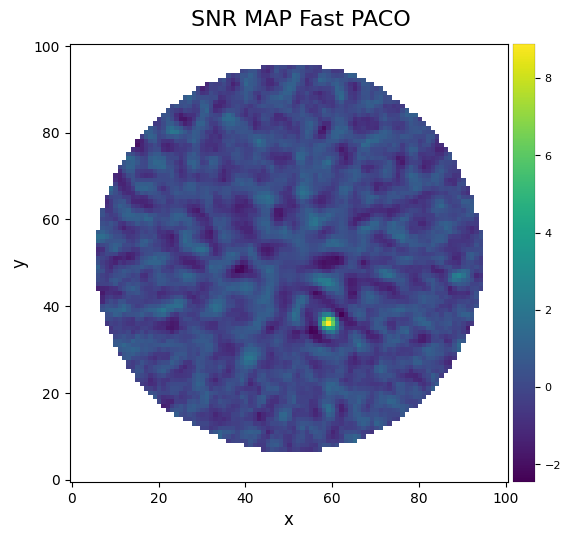

In [ ]:
from src.fast_paco import FastPACO

# Initialize Fast PACO with the required parameters
fast_paco = FastPACO(cube=cube, angles=derotation_angs, psf=psf, fwhm=fwhm, verbose=True)

# Run Fast PACO, Fast PACO does not support GPU acceleration, but it supports CPU multiprocessing
fast_snr, fast_flux = fast_paco.run(cpu = cpu_count()//2)

plot_frames((fast_snr, fast_flux), title=["SNR Map Fast PACO", "Flux Map Fast PACO"])

### PACO estimation (Algorithm 3 of the paper)

In [ ]:
source_location = (0, 0)  # You should set this to the pixel coordinates of the detected source

estimated_flux, _, _, _ = paco.estimate_flux_at(
        phi0=source_location,
        eps=0.0005,
        max_iter=100,
)
print(f"Estimated flux at {source_location}: {estimated_flux}")


You can also set an initial guess for the flux with the `initial_est` parameter, that guess could be the estimated flux from PACO in the source location, this could help with the convergence of the algorithm.

# Aditional: Contrast Curve for PACO (VIP Pipeline)

In [ ]:
import numpy as np
from scipy.stats import norm
from hciplot import plot_frames
from vip_hci.fm import cube_planet_free, normalize_psf
from vip_hci.config import VLT_NACO
from vip_hci.fits import open_fits
from src.full_paco import FullPACO

# --- 1. Data Loading and Setup ---
print("Loading data...")
pxscale_naco = VLT_NACO['plsc']

psf_path = 'systems/betapic/median_unsat.fits'
cube_path = 'systems/betapic/center_im.fits'
derotation_angs_path = 'systems/betapic/rotnth.fits'

cube = open_fits(cube_path)
psf = open_fits(psf_path)
angs = open_fits(derotation_angs_path)

psfn, _, fwhm = normalize_psf(psf, full_output=True, force_odd=False)

# --- 2. Create the Planet-Free Cube ---
# Define the known planet's parameters to be subtracted
r_b = 0.452 / pxscale_naco
theta_b = 211.2 + 90
f_b = 648.2

print("Creating the planet-free data cube...")
cube_emp = cube_planet_free([(r_b, theta_b, f_b)], cube, angs, psfn=psfn)

# --- 3. Run PACO on the Planet-Free Cube ---
print("Running PACO algorithm on the planet-free cube...")
# Note: PACO is run on `cube_emp`, not the original `cube`
paco = FullPACO(cube=cube_emp, angle_list=angs, psf=psfn, fwhm=fwhm,
                  pixscale=pxscale_naco, verbose=True)

# Note: use_gpu=True requires a compatible NVIDIA GPU and CUDA setup
snr_map = paco.run(use_gpu=True) 

# --- 4. Process S/N Map for Distribution Analysis ---
print("Analyzing the S/N map distribution...")
# Flatten the 2D S/N map into a 1D array and remove non-finite values (NaN, inf)
snr_values = snr_map[np.isfinite(snr_map)]

# --- 5. Generate the Histogram and Theoretical Gaussian ---
# Calculate the histogram of the S/N values
hist_counts, bin_edges = np.histogram(snr_values, bins=200, density=False)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Normalize the histogram to create a Probability Density Function (PDF)
bin_width = bin_edges[1] - bin_edges[0]
pdf_snr = hist_counts / (np.sum(hist_counts) * bin_width)

# Generate the theoretical standard Gaussian PDF (mean=0, std=1)
x_gauss = np.linspace(snr_values.min(), snr_values.max(), 500)
pdf_gauss = norm.pdf(x_gauss, loc=0, scale=1)


plot_frames(snr_map, title='S/N Map')

In [ ]:
# This is a modified contrast curve version as the original from VIP has trouble with the algo_class parameter
# and the handling of the cube_emp input when it has NaN values. 

from vip_hci.metrics import contrast_curve

starphot = 764939.6

cc_1 = contrast_curve(cube_emp, angs, psf, fwhm=fwhm, pxscale=pxscale_naco, starphot=starphot, 
                      sigma=5, nbranch=3, algo = None, debug=True, algo_class=paco, fc_snr=10)